# 04 Simulation — カメラ配置・鹿ルート・Perfect Observation

作成済みCaseを読み込み，Pythonの宣言と地図上のWaypointから実験条件を作る．YAMLは再現用の生成物であり，通常は直接編集しない．

## 実験とCaseの指定

実験の保存名，使用する農場Case，設定の版番号を指定する．

In [1]:
experiment_id = "miyota-v3-phase7"  # 実験条件一式を保存・識別する名前
case_id = "MiyotaMtBase_gsi_3km_v3"  # 使用する農場Caseの名前
configuration_version = "v1"  # 条件を変更して保存するときにv2，v3へ上げる版番号

## カメラ配置と観測条件

比較する配置方式と，観測ポール1本あたりのカメラ台数・視野・観測距離を指定する．リストに並べた配置と台数を全て実験する．

In [2]:
# 使用する配置方式を(方式名, 値)で並べる．記載した方式を全て実験する．
camera_placements = [
    ("grid", 40.0),  # 40 m間隔の格子状に観測点を置く
    ("uniform", 100),  # 牧場内へ観測点を100箇所，均等に分散させる
]

camera_counts = [6]  # 1本の観測ポールへ取り付けるカメラ台数．複数値も指定可能

camera_settings = {
    "pole_height_m": 5.0,  # 地面からカメラまでの高さ（m）
    "horizontal_fov_deg": 60.0,  # カメラ1台の水平方向の視野角（度）
    "vertical_fov_deg": 48.0,  # カメラ1台の垂直方向の視野角（度）
    "max_observation_distance_m": 42.0,  # 鹿を観測可能とみなす最大距離（m）
    "observation_interval_s": 1.0,  # カメラが観測結果を出す間隔（秒）
    "pitch_target_height_m": 0.75,  # カメラを向ける鹿の基準高さ（m）
    "pitch_reference_distance_m": 20.0,  # 下向き角度を決める基準距離（m）
}

## 鹿ルートの生成条件

同じWaypointから生成するルート方式と乱数seedを指定する．記載した方式とseedを全て実験する．

In [3]:
# 各Waypoint Setから，ここに並べた鹿ルートを全て生成する．
route_methods = ["smooth", "meandering"]  # 滑らかな経路と蛇行経路を両方実験する

route_planning_settings = {  # smoothとmeanderingで共通の障害物回避条件
    "auto_avoid_prohibited": True,  # 建物・移動禁止セルをA*で自動迂回する
    "snap_waypoints": True,  # 禁止セル上のWaypointを近い移動可能セルへ補正する
    "snap_radius_m": 30.0,  # Waypointを自動補正できる最大距離（m）
    "obstacle_clearance_m": 2.0,  # 建物・禁止セルから確保する最低余裕（m）
    "difficult_cost_multiplier": 4.0,  # 移動困難セルを避けやすくする経路コスト倍率
}

route_settings = {
    "smooth": {  # Waypointを必ず通過する滑らかな曲線
        **route_planning_settings,  # 共通のWaypoint補正・障害物回避条件
        "smoothing_tension": 0.0,  # 0は自然な曲線，1へ近づけるほどWaypoint付近を絞る
    },
    "meandering": {  # 蛇行型だけで使用する追加条件
        **route_planning_settings,  # 共通のWaypoint補正・障害物回避条件
        "smoothing_tension": 0.0,  # 蛇行の基準となる滑らかな曲線の張り具合
        "max_lateral_offset_m": 5.0,  # 基準線から左右へずれる最大距離（m）
        "meander_interval_m": 20.0,  # 蛇行の向きが変わるおおよその間隔（m）
    },
}
seeds = [42]  # 乱数の再現用番号．複数値を並べると各seedを実験する
tracker_methods = ["last_observation", "constant_velocity"]  # 全て実行するTracker
tracker_seed = 42  # Trackerの再現用seed

## 可視評価と移動時間の条件

可視範囲を調べる細かさ，鹿の高さ，移動速度，シミュレーションの時間刻みを指定する．

In [4]:
visibility_settings = {
    "preview_cell_size_m": 40.0,  # 高速な可視範囲プレビューの間隔（m）
    "intermediate_cell_size_m": 10.0,  # 中間確認用の可視評価間隔（m）
    "evaluation_cell_size_m": 1.0,  # 正式な可視評価で使う間隔（m）
    "deer_height_m": 1.5,  # 可視判定に使う鹿の身長（m）
    "sample_heights_m": [0.0, 0.75, 1.5],  # 足元・胴・頭を判定する高さ（m）
    "observation_position_error": {  # 将来の頑健性確認用．初期実験では無効
        "enabled": False,  # Falseなら現在のPerfect Observationを維持する
        "model": "uniform_disk",  # 近隣の円内へ一様にずらす方式
        "radius_m": 2.0,  # enabled=True時の最大位置ずれm
        "standard_deviation_m": 0.0,  # gaussian方式で使う標準偏差m
        "seed": 42,  # 同じ誤差を再現するseed
    },
}
simulation_settings = {
    "speed_mps": 1.5,  # 確定ルート上を進む鹿の速度（m/s）
    "step_s": 1.0,  # シミュレーション時刻を進める刻み（秒）
}

## 群れ構成の条件

ここへ並べた群れProfileを，全カメラ配置・全確定ルート・全seedと組み合わせて実験する．個体は確定ルートへ追従しながら間隔を保ち，建物と移動禁止セルを回避する．

In [ ]:
herd_profiles = [
    {
        "profile_id": "herd-small",  # 群れ構成を識別する名前
        "deer_count": 5,  # 群れの総個体数
        "adult_count": 3,  # 大人の個体数
        "juvenile_count": 2,  # 子供の個体数
        "formation": "cluster",  # リーダー周辺へまとまる配置
        "group_radius_m": 10.0,  # 群れ中心からの標準半径m
        "minimum_separation_m": 2.0,  # 個体同士の最低間隔m
        "follower_delay_s": 2.0,  # 追従個体がリーダーより遅れる秒数
        "speed_variation_mps": 0.15,  # 個体ごとの速度差m/s
    },
    {
        "profile_id": "herd-medium",
        "deer_count": 10,
        "adult_count": 7,
        "juvenile_count": 3,
        "formation": "cluster",
        "group_radius_m": 18.0,
        "minimum_separation_m": 2.0,
        "follower_delay_s": 3.0,
        "speed_variation_mps": 0.2,
    },
]

## Waypoint Setの作成数

今回は地図GUIから異なる3通りのWaypoint Setを作る．各Setへ`smooth`と`meandering`を適用するため，合計6本の確定ルートを生成する．件数は将来増やせる．

In [5]:
required_waypoint_set_count = 2  # 今回GUIで作成・保存する異なるWaypoint Setの数
initial_waypoint_sets = {}  # 保存済みSetはGUIが自動読込するため，通常は空でよい

## 新しい方式の追加方法

通常は上の設定セルだけを編集する．標準方式は`grid`と`uniform`である．独自方式が必要な場合だけ，次のPythonファイルを追加する．

### カメラ配置を追加する

1. [配置方式の説明](placement/README.md)を開く．
2. [配置方式フォルダ](placement/)へ`方式名.py`を作る．例：`ridge_priority.py`．
3. ファイル内へ`generate(environment_case, definition)`を書き，共通の`ObservationPointLayout`を返す．入力値は`definition.parameters["value"]`で読める．
4. 上の設定へ`("ridge_priority", 100)`を追加する．ファイル名と方式名は同じにする．

### 鹿ルートを追加する

1. [ルート方式の説明](behavior/routes/README.md)を開く．
2. [ルート方式フォルダ](behavior/routes/)へ`方式名.py`を作る．例：`forest_edge.py`．
3. ファイル内へ`generate(environment_case, definition, waypoint_set)`を書き，検証済みの`ResolvedRoute`を返す．
4. 上の`route_methods`へ`"forest_edge"`を追加する．追加条件は`route_settings["forest_edge"]`へ書く．

生成結果は[自動生成YAML](experiments/generated/)へ保存される．ここは再現記録なので通常は直接編集しない．Notebookへアルゴリズム本体は書かず，同じ設定とseedから同じ結果を返すPython実装にする．

In [ ]:
ENABLE_WAYPOINT_EDITOR = True  # Trueにすると地図GUIで複数のWaypoint Setを作成する
VISIBILITY_MAP_CELL_SIZE_M = 10.0  # 可視範囲図を計算する間隔（m）．正式評価は1.0
RUN_FORMAL_1M_EVALUATION = True  # Trueにすると時間のかかる1 m間隔の正式評価を行う
FORMAL_VISIBILITY_WORKERS = 4  # 1 m正式評価で使うCPUプロセス数．Jetsonでは4を推奨
OVERWRITE_GENERATED_YAML = True  # TrueにするとNotebookから生成する設定YAMLを更新する
OVERWRITE_CASE_RESULTS = False  # Trueにすると同名のCase内結果を上書きするため通常はFalse

In [7]:
from pathlib import Path
import os
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from field_environment import find_repository_root, load_case, plot_experiment_environment
from field_campost import (
    generate_placement_layout, load_observation_point_layout,
    plot_observation_point_layout_2d, save_observation_point_layout,
)
from field_sim import (
    VisibilityConfig, WaypointSet, WaypointSpec, as_binary_visibility_map, author_experiment,
    compute_visibility_map, generate_resolved_route, load_visibility_map,
    plot_binary_visibility_map, plot_visibility_failures, plot_visibility_map,
    save_visibility_map_metrics, visibility_map_metrics,
    validate_waypoint_set,
)

REPOSITORY_ROOT = find_repository_root()
CASES_ROOT = Path(os.environ.get("WILDLIFE_CASES_ROOT", REPOSITORY_ROOT / "cases"))
GENERATED_EXPERIMENTS_ROOT = Path(os.environ.get(
    "WILDLIFE_EXPERIMENTS_ROOT", REPOSITORY_ROOT / "workspace/experiments/generated"
))
WAYPOINT_LIBRARY_ROOT = Path(os.environ.get(
    "WILDLIFE_WAYPOINT_ROOT", REPOSITORY_ROOT / "workspace/experiments/waypoint_sets"
))

## 1．Caseと保存済みWaypointを読み込む

Waypointは地形取得範囲全体へ置ける．赤は建物等の移動禁止セル，橙は移動困難セルである．赤い地点をクリックした場合は設定距離内の移動可能セルへ自動補正する．牧場外は注意とし，Waypoint間で禁止領域に当たる経路は確定時に自動迂回する．

In [8]:
environment_case = load_case(CASES_ROOT, case_id)
initial_sets = []
if "initial_waypoint_sets" in globals():
    for set_id, coordinates in initial_waypoint_sets.items():
        initial_sets.append(WaypointSet(
            waypoint_set_id=set_id, case_id=case_id,
            waypoints=tuple(
                WaypointSpec(id=f"WP{index + 1:03d}", x_m=x_m, y_m=y_m)
                for index, (x_m, y_m) in enumerate(coordinates)
            ),
        ))
elif "waypoint_set_id" in globals() and "initial_waypoints" in globals():
    initial_sets.append(WaypointSet(
        waypoint_set_id=waypoint_set_id, case_id=case_id,
        waypoints=tuple(
            WaypointSpec(id=f"WP{index + 1:03d}", x_m=x_m, y_m=y_m)
            for index, (x_m, y_m) in enumerate(initial_waypoints)
        ),
    ))
print(f"Case: {case_id}")
print(f"Pythonで指定した初期Waypoint Set: {len(initial_sets)}件")

Case: MiyotaMtBase_gsi_3km_v3
Pythonで指定した初期Waypoint Set: 0件


## 2．地図上で3通りのWaypoint Setを作る

このセルを実行したら，地図上でWaypointを順番に追加する．赤い移動禁止セル上を選ぶと近い移動可能地点へ補正される．`smooth表示`と`meandering表示`で自動迂回を確認し，`Setを保存`を押す．`新規`を押して必要数だけ繰り返す．保存先は`workspace/experiments/waypoint_sets/<experiment_id>/`であり，保存済みWaypointは再利用できる．

In [9]:
if ENABLE_WAYPOINT_EDITOR:
    get_ipython().run_line_magic("matplotlib", "widget")
    from field_sim.notebook import WaypointSetManager
    waypoint_manager = WaypointSetManager(
        environment_case,
        storage_directory=WAYPOINT_LIBRARY_ROOT / experiment_id,
        required_count=required_waypoint_set_count,
        route_methods=route_methods,
        route_settings=route_settings,
        route_seed=seeds[0],
        initial_sets=initial_sets,
    )
    waypoint_manager.display()
else:
    waypoint_manager = None
    print("Pythonで指定した初期Waypoint Setを使用する．")

## 3．Python宣言から実験条件を生成する

配置，ルート，seedの全組合せを解決し，コメント付きYAMLを`workspace/experiments/generated/<experiment_id>/`へ保存する．このYAMLは再現・比較用の生成物である．

In [10]:
active_waypoint_sets = (
    waypoint_manager.get_waypoint_sets() if waypoint_manager is not None else tuple(initial_sets)
)
if not active_waypoint_sets:
    raise ValueError("Waypoint Setがない．GUIで保存するかinitial_waypoint_setsへ指定すること．")
authored = author_experiment(
    GENERATED_EXPERIMENTS_ROOT,
    experiment_id=experiment_id,
    case_id=case_id,
    camera_placements=camera_placements,
    camera_counts=camera_counts,
    camera_settings=camera_settings,
    waypoint_sets=active_waypoint_sets,
    route_methods=route_methods,
    route_settings=route_settings,
    seeds=seeds,
    placement_seed=seeds[0],
    route_seed=seeds[0],
    version=configuration_version,
    visibility=visibility_settings,
    simulation=simulation_settings,
    herd_profiles=herd_profiles,
    tracker_methods=tracker_methods,
    tracker_seed=tracker_seed,
    overwrite=OVERWRITE_GENERATED_YAML,
)
loaded_plan = authored.loaded_plan
print(f"Waypoint Set: {len(active_waypoint_sets)}件")
print(f"確定ルート: {len(authored.route_definitions)}本")
print(f"生成YAML: {authored.plan_path}")
print(f"全組合せ: {len(loaded_plan.combinations)}")
display(loaded_plan.dataframe())

Waypoint Set: 2件
確定ルート: 4本
生成YAML: /workspace/workspace/experiments/generated/miyota-v3-phase7/experiment.yaml
全組合せ: 8


,combination_id,placement_file,route_file,seed
0,grid-40m-cam6-v1__route-001-v1-smooth-v1__seed42,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
1,grid-40m-cam6-v1__route-001-v1-meandering-v1__...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
2,grid-40m-cam6-v1__route-002-v1-smooth-v1__seed42,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
3,grid-40m-cam6-v1__route-002-v1-meandering-v1__...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
4,uniform-100points-cam6-v1__route-001-v1-smooth...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
5,uniform-100points-cam6-v1__route-001-v1-meande...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
6,uniform-100points-cam6-v1__route-002-v1-smooth...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42
7,uniform-100points-cam6-v1__route-002-v1-meande...,/workspace/workspace/experiments/generated/miy...,/workspace/workspace/experiments/generated/miy...,42


## 4．全カメラ配置を生成・確認する

`camera_placements × camera_counts`を全て生成する．既存の同一IDが異なる内容ならエラーとし，暗黙には置き換えない．


=== grid-40m-cam6-v1 ===
観測点 330，カメラ 1,980


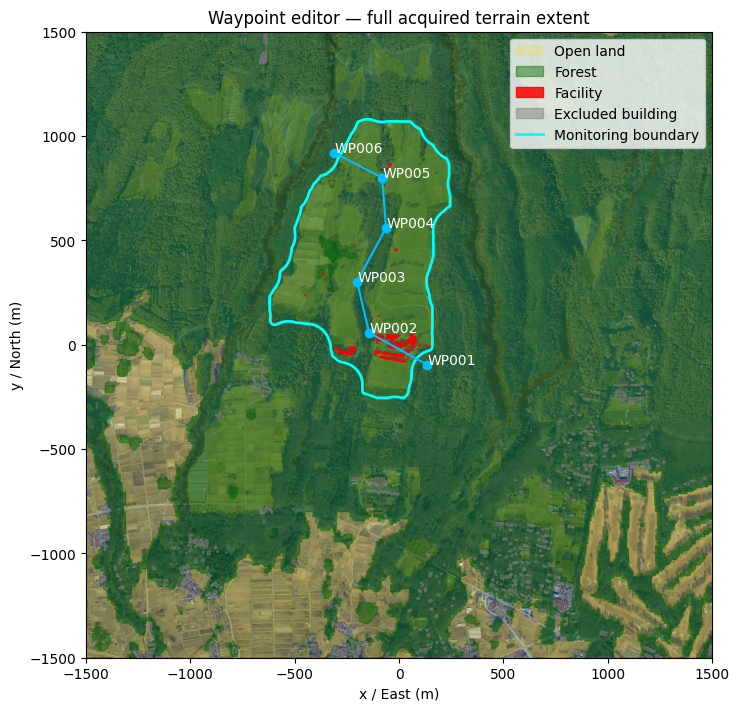

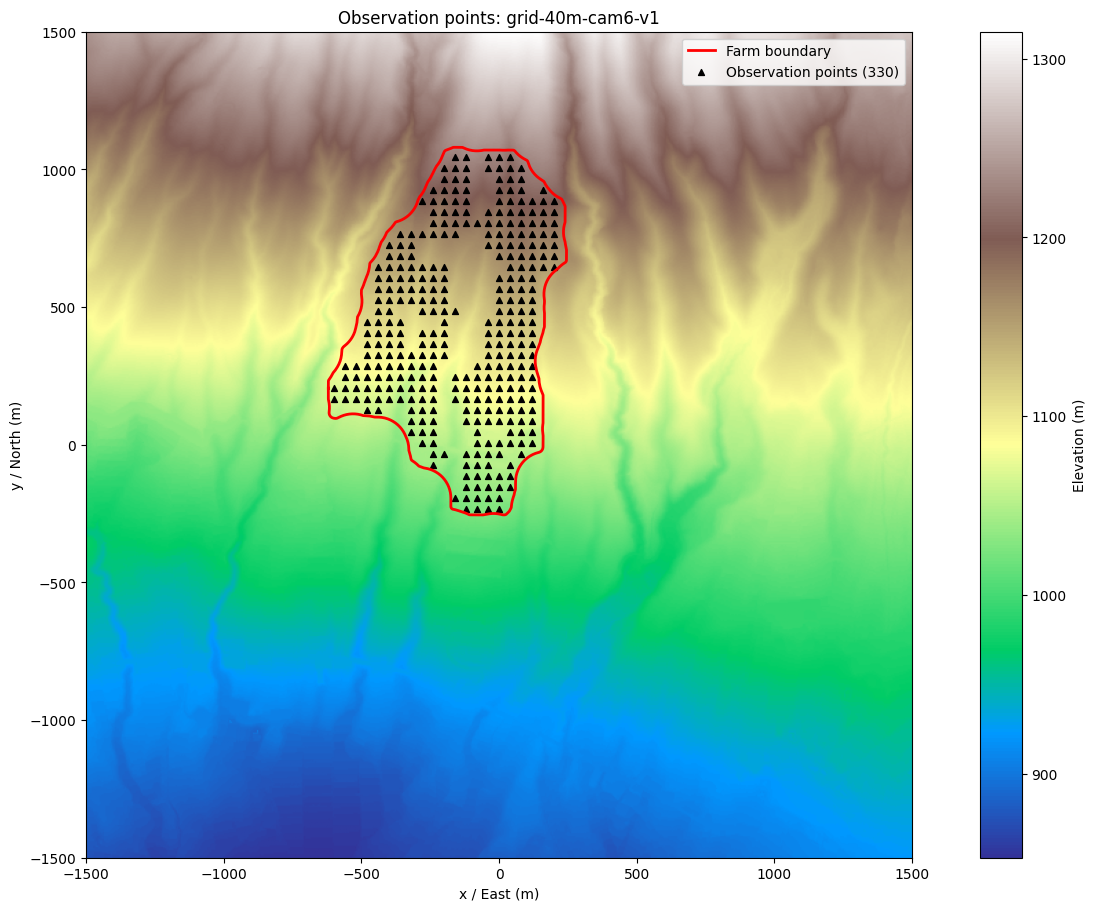


=== uniform-100points-cam6-v1 ===
観測点 100，カメラ 600


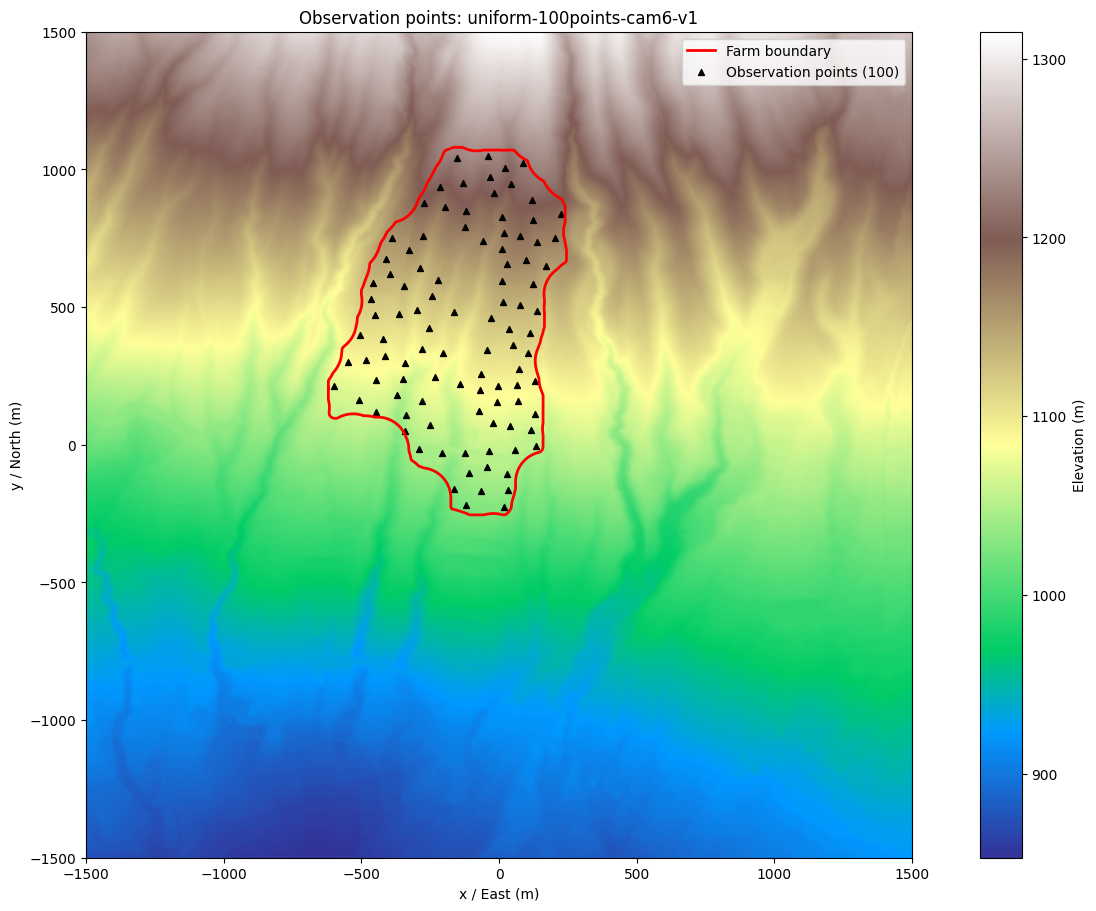

In [11]:
get_ipython().run_line_magic("matplotlib", "inline")
layouts = {}
for definition in authored.placement_definitions:
    generated = generate_placement_layout(environment_case, definition)
    try:
        save_observation_point_layout(CASES_ROOT, case_id, generated, overwrite=OVERWRITE_CASE_RESULTS)
        layout = generated
    except FileExistsError:
        stored = load_observation_point_layout(CASES_ROOT, case_id, generated.layout_id)
        if stored != generated:
            raise ValueError(f"同じlayout_idに異なる配置が保存済みである: {generated.layout_id}")
        layout = stored
    layouts[layout.layout_id] = layout

for layout in layouts.values():
    print(f"\n=== {layout.layout_id} ===")
    print(f"観測点 {len(layout.points):,}，カメラ {len(layout.camera_layout.cameras):,}")
    figure, _ = plot_observation_point_layout_2d(environment_case, layout)
    figure.set_size_inches(12, 9)
    plt.show()
    plt.close(figure)

## 5．全Waypoint Setからルートを生成・確認する

保存したWaypoint Setへ`smooth`と`meandering`を適用する．禁止地点のWaypointは近い移動可能セルへ補正し，Waypoint間の建物・移動禁止領域はA*で迂回する．補正量，迂回区間，曲線・蛇行幅の調整は注意として出力し，確定経路と再現条件をCaseの`routes/`へ保存する．

route-001-v1-smooth-v1: 1379.3 m，詳細点 1,385
自動迂回区間: [1]
注意: WP001: outside farm boundary
注意: WP001: inside forest
注意: WP002: inside forest
注意: WP003: inside forest
注意: WP004: inside forest
注意: WP006: outside farm boundary
注意: WP006: inside forest
注意: A*で移動禁止領域を迂回した区間: 1
注意: 移動禁止領域を避けるため曲線強度を0から0.75へ調整した
注意: route includes positions outside the farm boundary
注意: route includes positions inside forest
既存の同名ルートを保持した．変更時はconfiguration_versionを上げること．
route-001-v1-meandering-v1: 1379.3 m，詳細点 1,385
自動迂回区間: [1]
注意: WP001: outside farm boundary
注意: WP001: inside forest
注意: WP002: inside forest
注意: WP003: inside forest
注意: WP004: inside forest
注意: WP006: outside farm boundary
注意: WP006: inside forest
注意: A*で移動禁止領域を迂回した区間: 1
注意: 移動禁止領域を避けるため曲線強度を0から0.75へ調整した
注意: 移動禁止領域を避けるため蛇行幅を5 mから0 mへ縮小した
注意: route includes positions outside the farm boundary
注意: route includes positions inside forest
既存の同名ルートを保持した．変更時はconfiguration_versionを上げること．
route-002-v1-smooth-v1: 2820.9 m，詳細点 2,828
自動迂回区間: [4, 5]
注意: WP

/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 30906 (\N{CJK UNIFIED IDEOGRAPH-78BA}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 12375 (\N{HIRAGANA LETTER SI}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 12383 (\N{HIRAGANA LETTER TA}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 40575 (\N{CJK UNIFIED IDEOGRAPH-9E7F}) missing from font(s) DejaVu Sans.
  figure.tight_layout()
/tmp/ipykernel_258646/2809452810.py:27: UserWarning: Glyph 12523 (\N{KATAKANA LE

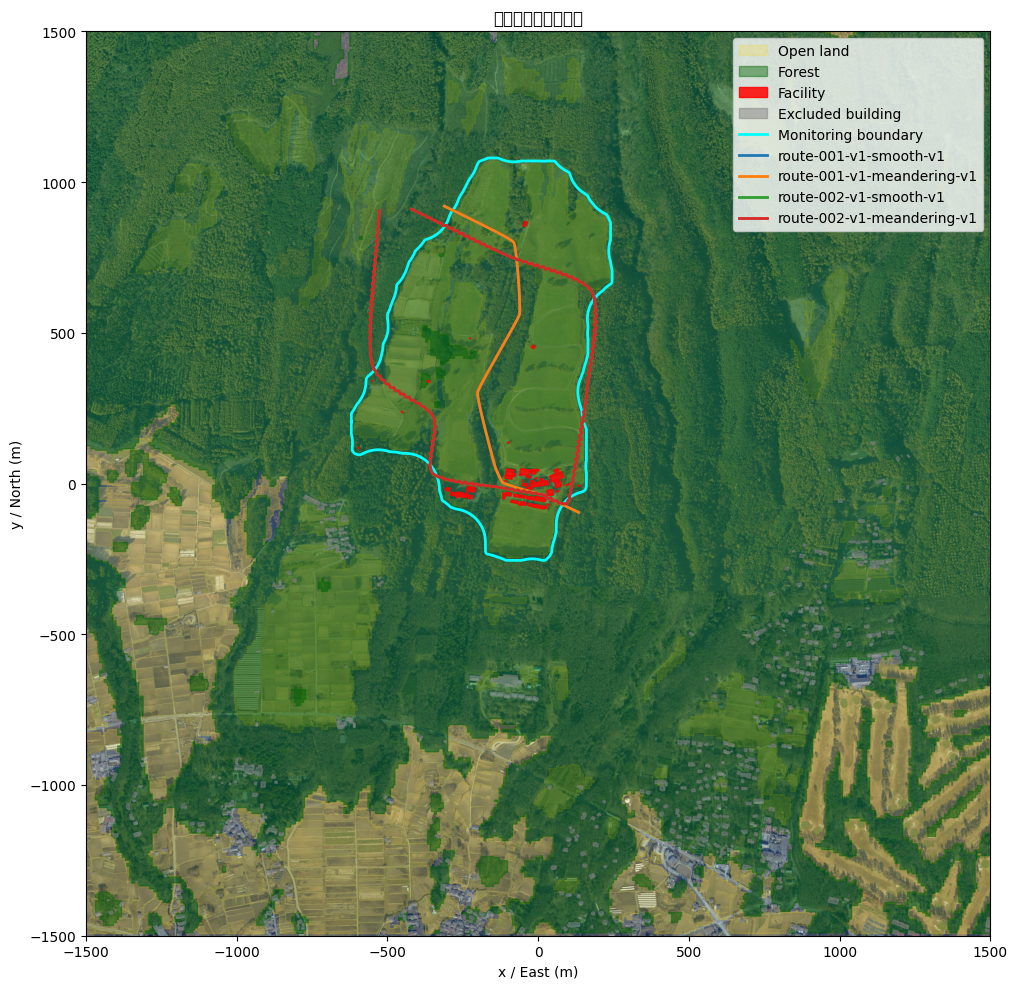

In [12]:
from field_sim import save_resolved_route
waypoint_sets_by_id = {item.waypoint_set_id: item for item in active_waypoint_sets}
routes = {}
for definition in authored.route_definitions:
    waypoint_set = waypoint_sets_by_id[definition.route_group_id]
    route = generate_resolved_route(environment_case, definition, waypoint_set)
    routes[route.definition.route_id] = route
    print(f"{route.definition.route_id}: {route.length_m:.1f} m，詳細点 {len(route.points):,}")
    if route.planning.get("used_astar_segments"):
        print(f"自動迂回区間: {route.planning['used_astar_segments']}")
    for adjustment in route.planning.get("waypoint_adjustments", []):
        if adjustment.get("reason"):
            print(f"Waypoint補正: {adjustment['waypoint_id']}，{adjustment['distance_m']:.1f} m")
    for warning in route.warnings:
        print(f"注意: {warning}")
    try:
        saved_route = save_resolved_route(CASES_ROOT, route, overwrite=OVERWRITE_CASE_RESULTS)
        print(f"保存: {saved_route}")
    except FileExistsError:
        print("既存の同名ルートを保持した．変更時はconfiguration_versionを上げること．")
figure, axis = plot_experiment_environment(environment_case)
figure.set_size_inches(14, 10)
for route in routes.values():
    axis.plot(route.points.x_m, route.points.y_m, linewidth=2, label=route.definition.route_id)
axis.set_title("確定した全鹿ルート")
axis.legend(loc="best")
figure.tight_layout()
plt.show()
plt.close(figure)

## 6．鹿の高さで可視範囲を評価する

設定した間隔の図は部分可視と失敗理由を確認する診断表示である．1 m正式評価では，同じカメラから足元・胴・頭がすべて見える地点だけを緑，農場内の不可視地点を赤，農場外を灰色で表示する．正式評価は複数CPUで計算し，途中結果を再利用する．


=== grid-40m-cam6-v1 ===
観測点 330，カメラ 1,980
10 m間隔の詳細可視評価


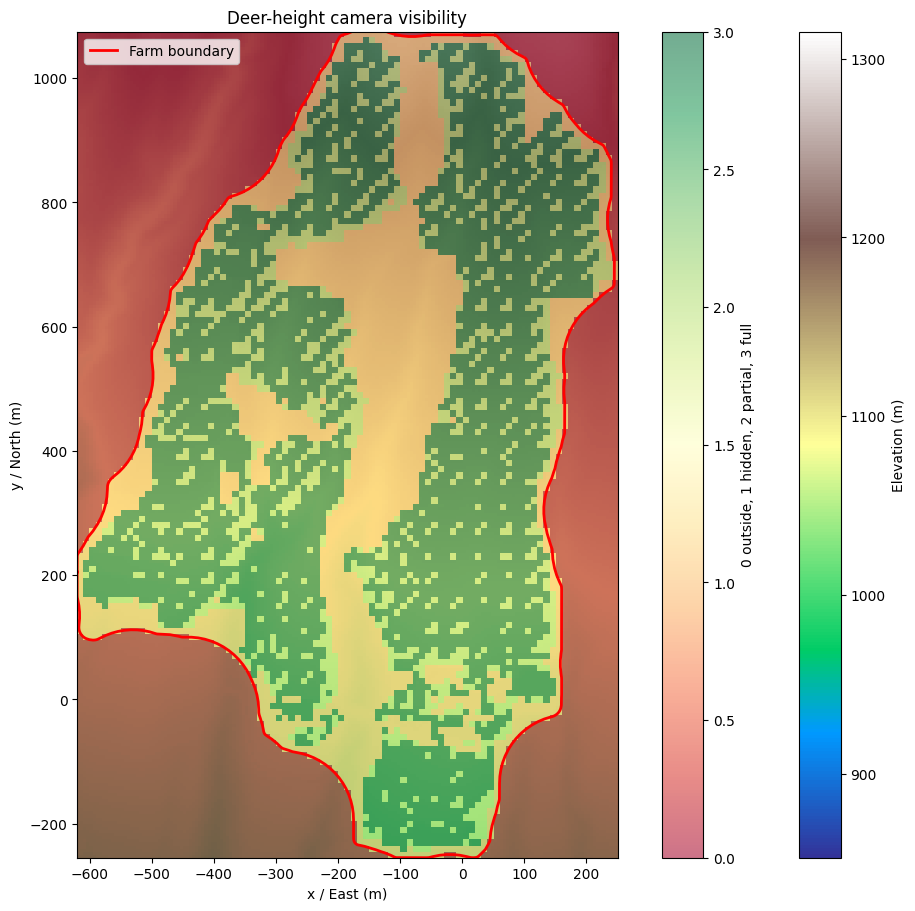

10 m間隔の主な不可視理由


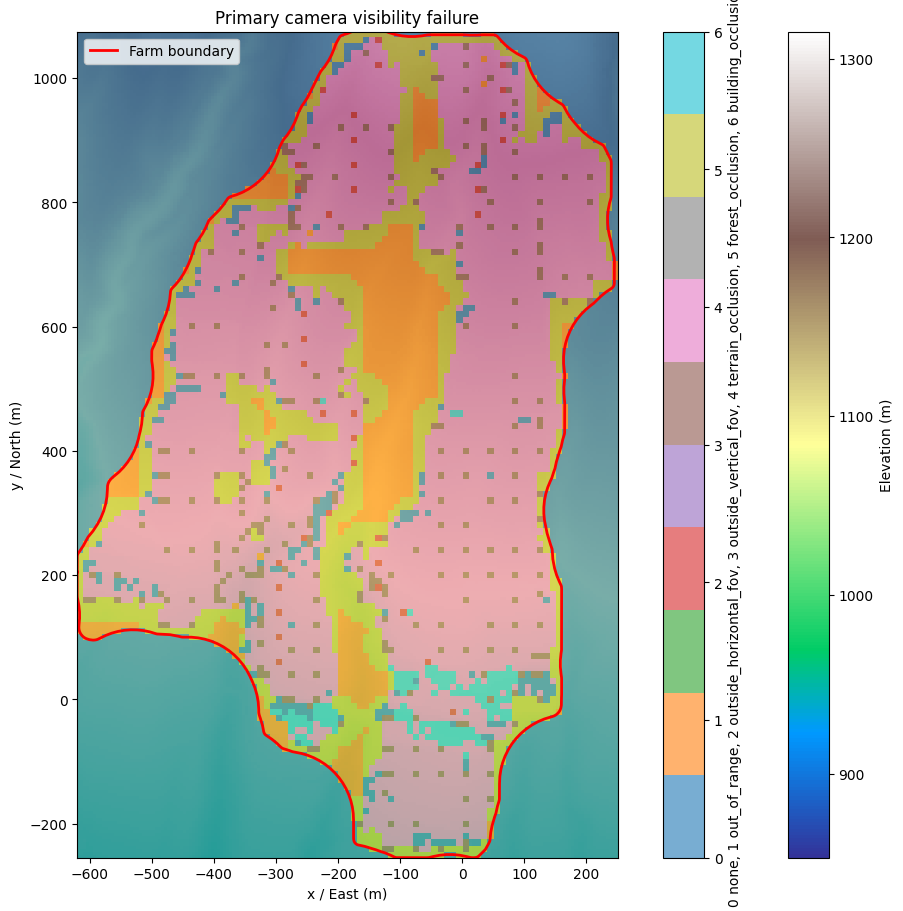

可視評価集計: /workspace/cases/MiyotaMtBase_gsi_3km_v3/visibility_maps/grid-40m-cam6-v1/coverage-metrics-10m.json
既存の1 m詳細評価を再利用し，二値画像だけを生成します．
1 m正式評価（緑: 可視，赤: 不可視，灰: 農場外）
正式判定: 同じカメラから足元・胴・頭がすべて見える地点を可視とします．
1 m正式評価集計: /workspace/cases/MiyotaMtBase_gsi_3km_v3/visibility_maps/grid-40m-cam6-v1/coverage-metrics-1m-binary.json


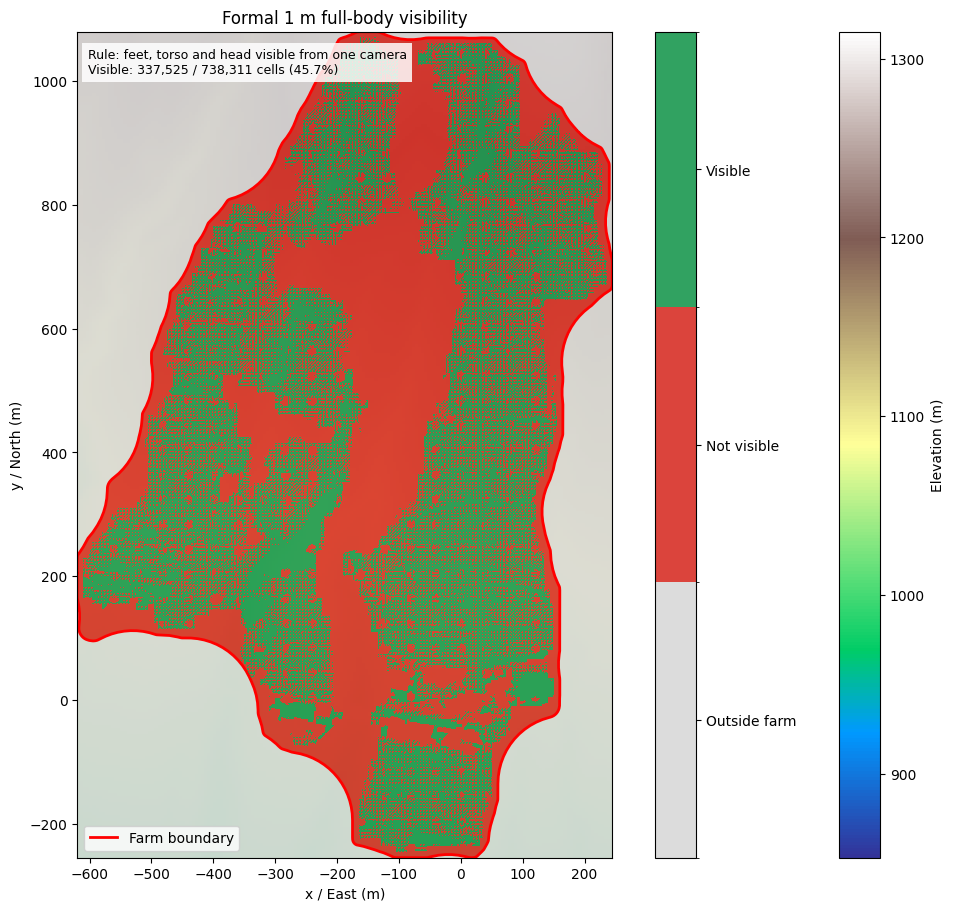


=== uniform-100points-cam6-v1 ===
観測点 100，カメラ 600
10 m間隔の詳細可視評価


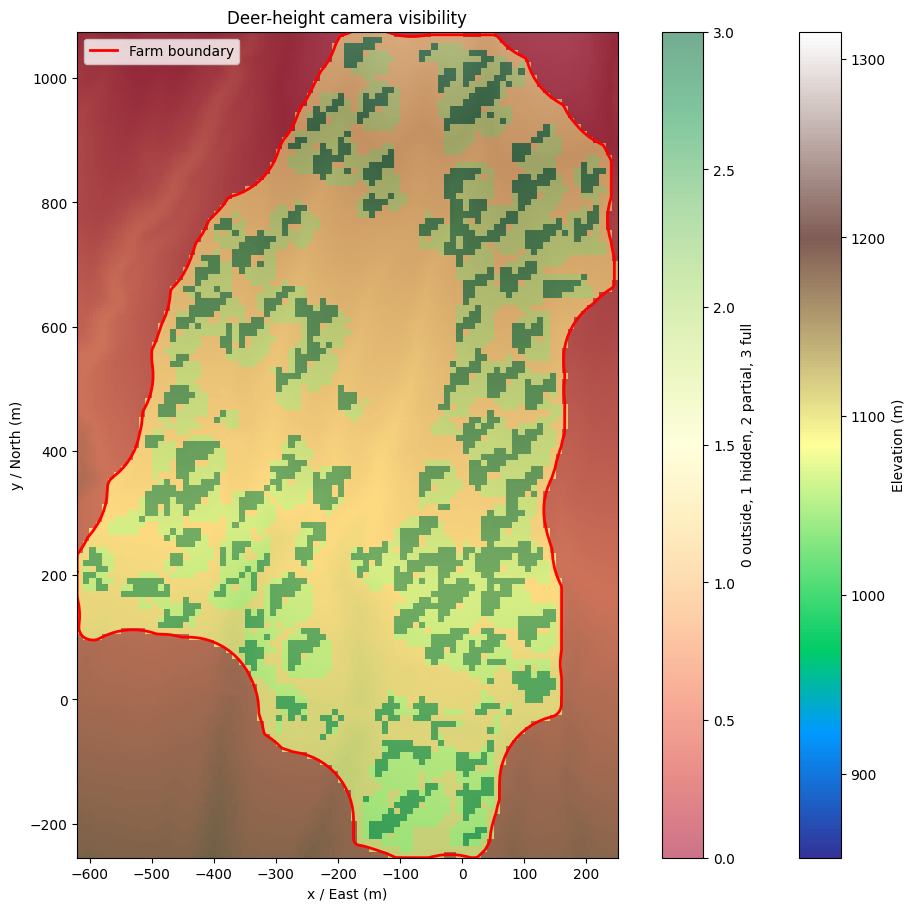

10 m間隔の主な不可視理由


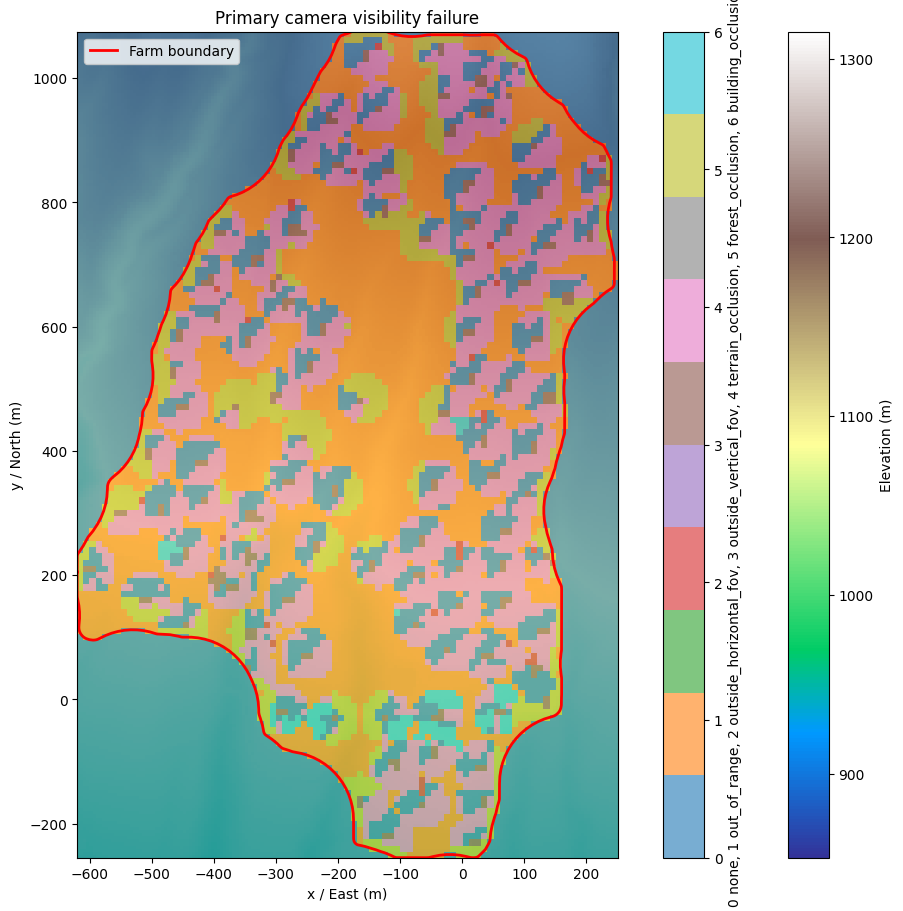

可視評価集計: /workspace/cases/MiyotaMtBase_gsi_3km_v3/visibility_maps/uniform-100points-cam6-v1/coverage-metrics-10m.json
1 m二値評価を4プロセスで実行します．
1 m正式評価（緑: 可視，赤: 不可視，灰: 農場外）
正式判定: 同じカメラから足元・胴・頭がすべて見える地点を可視とします．
1 m正式評価集計: /workspace/cases/MiyotaMtBase_gsi_3km_v3/visibility_maps/uniform-100points-cam6-v1/coverage-metrics-1m-binary.json


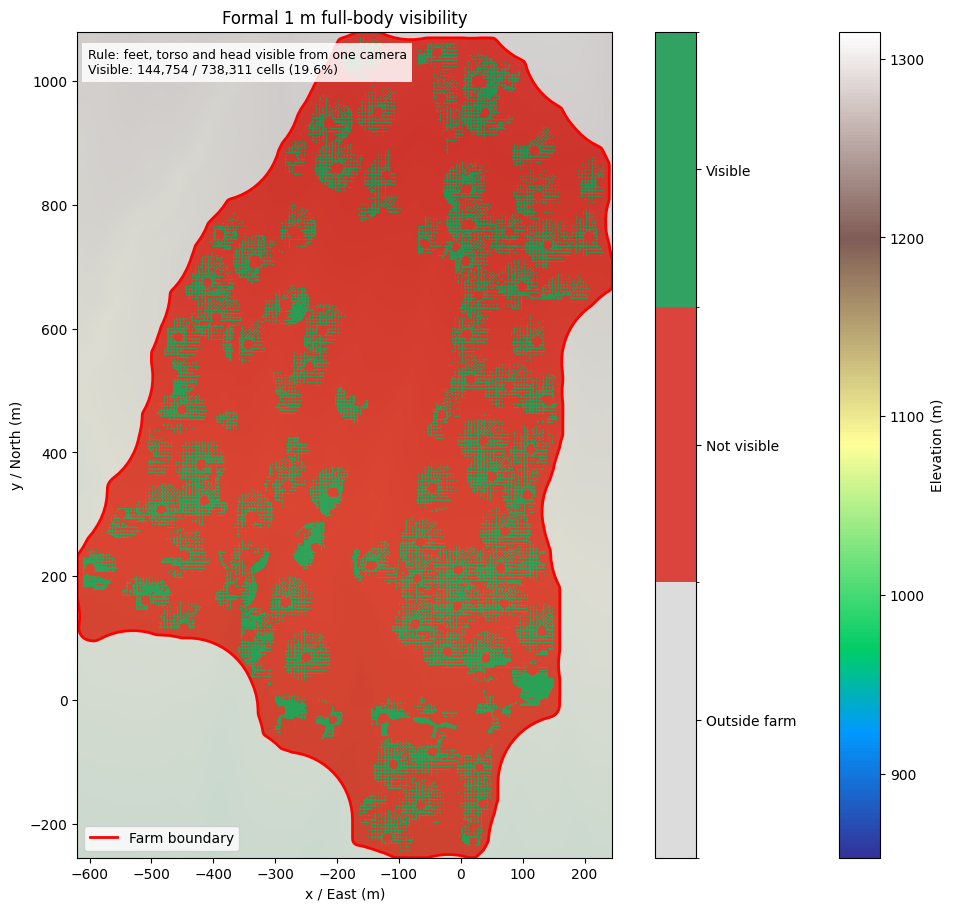


=== 配置別の可視評価比較 ===
grid-40m-cam6-v1: 観測点 330，カメラ 1,980，可視率 45.7%，不可視率 54.3%
uniform-100points-cam6-v1: 観測点 100，カメラ 600，可視率 19.6%，不可視率 80.4%


In [13]:
visibility_config = VisibilityConfig(
    deer_height_m=1.5, sample_heights_m=(0.0, 0.75, 1.5), observation_rule="full_body"
)
visibility_results = {}
comparison_results = []
for layout in layouts.values():
    print(f"\n=== {layout.layout_id} ===")
    print(f"観測点 {len(layout.points):,}，カメラ {len(layout.camera_layout.cameras):,}")
    visibility_directory = CASES_ROOT / case_id / "visibility_maps" / layout.layout_id
    preview_checkpoint = visibility_directory / f"visibility-{VISIBILITY_MAP_CELL_SIZE_M:g}m.npz"
    visibility_map = compute_visibility_map(
        environment_case, layout, visibility_config,
        cell_size_m=VISIBILITY_MAP_CELL_SIZE_M, checkpoint_path=preview_checkpoint,
    )
    print(f"{VISIBILITY_MAP_CELL_SIZE_M:g} m間隔の詳細可視評価")
    figure, _ = plot_visibility_map(environment_case, visibility_map)
    figure.set_size_inches(12, 9)
    plt.show()
    plt.close(figure)
    print(f"{VISIBILITY_MAP_CELL_SIZE_M:g} m間隔の主な不可視理由")
    figure, _ = plot_visibility_failures(environment_case, visibility_map)
    figure.set_size_inches(12, 9)
    plt.show()
    plt.close(figure)
    metrics_path = save_visibility_map_metrics(
        visibility_directory / f"coverage-metrics-{VISIBILITY_MAP_CELL_SIZE_M:g}m.json",
        visibility_map,
    )
    comparison_map = visibility_map
    print(f"可視評価集計: {metrics_path}")
    if RUN_FORMAL_1M_EVALUATION:
        detailed_checkpoint = visibility_directory / "visibility-1m.npz"
        binary_checkpoint = visibility_directory / "visibility-1m-binary.npz"
        if detailed_checkpoint.is_file():
            print("既存の1 m詳細評価を再利用し，二値画像だけを生成します．")
            formal_map = load_visibility_map(detailed_checkpoint)
        else:
            print(f"1 m二値評価を{FORMAL_VISIBILITY_WORKERS}プロセスで実行します．")
            formal_map = compute_visibility_map(
                environment_case, layout, visibility_config,
                cell_size_m=1.0, checkpoint_path=binary_checkpoint,
                checkpoint_row_count=8, worker_count=FORMAL_VISIBILITY_WORKERS,
                binary_only=True,
            )
        formal_binary_map = as_binary_visibility_map(formal_map)
        formal_metrics_path = save_visibility_map_metrics(
            visibility_directory / "coverage-metrics-1m-binary.json", formal_binary_map
        )
        print("1 m正式評価（緑: 可視，赤: 不可視，灰: 農場外）")
        print("正式判定: 同じカメラから足元・胴・頭がすべて見える地点を可視とします．")
        print(f"1 m正式評価集計: {formal_metrics_path}")
        figure, _ = plot_binary_visibility_map(environment_case, formal_binary_map)
        figure.set_size_inches(12, 9)
        plt.show()
        plt.close(figure)
        comparison_map = formal_binary_map
    visibility_results[layout.layout_id] = comparison_map
    metrics = visibility_map_metrics(comparison_map)
    comparison_results.append((
        layout.layout_id, len(layout.points), len(layout.camera_layout.cameras),
        metrics["class_rates"]["fully_visible"],
        1.0 - metrics["class_rates"]["fully_visible"],
    ))

print("\n=== 配置別の可視評価比較 ===")
for layout_id, point_count, camera_count, visible_rate, hidden_rate in comparison_results:
    print(
        f"{layout_id}: 観測点 {point_count:,}，カメラ {camera_count:,}，"
        f"可視率 {visible_rate:.1%}，不可視率 {hidden_rate:.1%}"
    )

## 7．実験計画を確認する

配置×ルート×群れ設定×seedの全組合せを確認する．NotebookではDataset，Observation，Trackerを実行しない．

In [ ]:
display(loaded_plan.dataframe())
print(f"保存済み実験計画: {authored.plan_path}")
print("シミュレーションと追跡は次のPython Runnerで実行する．")

## 8．群れ設定を確認する

群れProfileと適用対象ルートを表で確認する．群れのシミュレーションはPython Runnerだけが実行する．

In [ ]:
import pandas as pd
display(pd.DataFrame(herd_profiles))
print(f"対象ルート: {len(routes):,}，seed: {seeds}")

## 9．実験RunnerとViewerのコマンドを出力する

Rerun Web Viewerを別プロセスで起動し，保存した実験計画をPython Runnerへ渡す．Genesis GUIが利用可能な場合は`--genesis-viewer`を付ける．

In [ ]:
BENCHMARK_ID = f"{experiment_id}-benchmark-v1"
try:
    plan_argument = authored.plan_path.relative_to(REPOSITORY_ROOT)
except ValueError:
    plan_argument = authored.plan_path
runner = (
    f"python3 workspace/run_experiments.py run --plan {plan_argument} "
    f"--benchmark-id {BENCHMARK_ID} --rerun-url 127.0.0.1:9876 "
    "--genesis-viewer --genesis-backend cpu"
)
print("[1] Rerun Web Viewer（別プロセス）")
print("python3 workspace/run_experiments.py serve-rerun")
print("\n[2] foreground実行")
print(runner)
print("\n[3] background実行")
log_path = f"cases/{case_id}/benchmarks/{BENCHMARK_ID}/runner.log"
print(f"mkdir -p cases/{case_id}/benchmarks/{BENCHMARK_ID}")
print(f"nohup {runner} > {log_path} 2>&1 &")